# 01 · Exploratory data analysis (on IBM LinuxONE)
Public Kaggle *Healthcare Provider Fraud Detection* data. Labels are **per provider**, not per claim.

In [1]:
import sys, os, platform, subprocess
sys.path.insert(0, os.path.expanduser("~/claimsense/src"))
import xgboost  # before torch (see training.py)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SHARED = os.path.expanduser("~/shared")
RAW = f"{SHARED}/data/raw"
print(platform.machine(), platform.platform())
print(subprocess.run("grep -E '^Type' /proc/sysinfo; lscpu | grep -io nnpa | head -1", shell=True, capture_output=True, text=True).stdout)

s390x Linux-6.8.0-147-generic-s390x-with-glibc2.39
Type:                 9175
Type 1 Percentage:    0
Type 2 Percentage:    0
Type 3 Percentage:    0
Type 4 Percentage:    0
Type 5 Percentage:    0
nnpa



In [2]:
from claimsense import data as D
claims, bene, labels = D.load_all(RAW)
print(f"claims {len(claims):,} | beneficiaries {len(bene):,} | providers {len(labels):,} | flagged providers {labels.label.sum()} ({labels.label.mean():.1%})")
print("date range", claims.ClaimStartDt.min().date(), "->", claims.ClaimStartDt.max().date())
claims.groupby("is_inpatient").InscClaimAmtReimbursed.describe()

claims 558,211 | beneficiaries 138,556 | providers 5,410 | flagged providers 506 (9.4%)
date range 2008-11-27 -> 2009-12-31


,count,mean,std,min,25%,50%,75%,max
is_inpatient,,,,,,,,
0,517737.0,286.334799,694.034343,0.0,40.0,80.0,200.0,102500.0
1,40474.0,10087.884074,10303.099402,0.0,4000.0,7000.0,12000.0,125000.0


38.1% of claims come from flagged providers (they are the big ones)


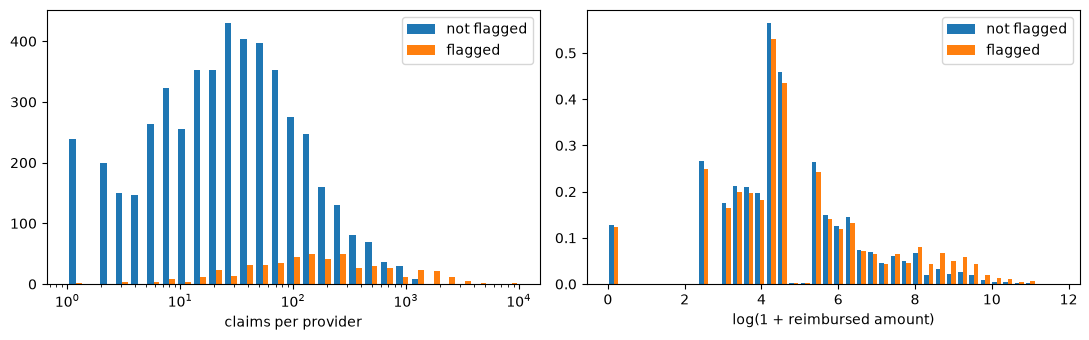

In [3]:
c = claims.merge(labels, on="Provider")
per_provider = c.groupby("Provider").agg(claims=("ClaimID", "size"), label=("label", "first"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist([per_provider.claims[per_provider.label == 0], per_provider.claims[per_provider.label == 1]], bins=np.logspace(0, 4, 30), label=["not flagged", "flagged"])
ax[0].set_xscale("log"); ax[0].set_xlabel("claims per provider"); ax[0].legend()
ax[1].hist([np.log1p(c.InscClaimAmtReimbursed[c.label == 0]), np.log1p(c.InscClaimAmtReimbursed[c.label == 1])], bins=40, density=True, label=["not flagged", "flagged"])
ax[1].set_xlabel("log(1 + reimbursed amount)"); ax[1].legend(); plt.tight_layout()
print(f"{c.label.mean():.1%} of claims come from flagged providers (they are the big ones)")

In [4]:
# Honest billing errors in the raw data: rules ClaimSense checks deterministically
from claimsense.features import hard_errors_batch
rules = hard_errors_batch(claims)
rules.sum().to_frame("claims")

,claims
after_death,0
end_before_start,0
discharge_before_admission,0
missing_attending,1508
no_coverage,2065
duplicate,33


Almost no deterministic errors exist in this public data (no claims after death, no swapped dates), so the demo simulator **injects** a small, labelled set of realistic errors and measures how many are caught. Missing attending physicians and claims for patients with no Part A/B coverage *do* occur naturally.